# NYC 311 Service Performance Analysis (2025)

**Business question:** NYC's 311 system handled 3.66 million service requests in 2025.
Which requests take longest to resolve, and do some neighborhoods get slower service
than others *for the same kind of problem*?

**Audience:** the Mayor's Office of Operations and agency performance teams.

**Data:** [NYC Open Data, 311 Service Requests from 2010 to Present](https://data.cityofnewyork.us/Social-Services/311-Service-Requests-from-2010-to-Present/erm2-nwe9),
all requests created 1 Jan to 31 Dec 2025. Extracted September 2026, so even
December requests have had 8+ months to close.

**Approach:**
1. Extract with the Socrata API (`src/extract.py`), load into DuckDB, and clean in SQL (`sql/01_staging.sql`).
2. Measure data quality before trusting any number.
3. Describe demand: what, when and how people report.
4. Measure performance by agency and complaint type.
5. Compare areas fairly with a **complaint-mix-adjusted** benchmark.

All queries live in `sql/`. This notebook runs them and interprets the results.

In [1]:
import sys
sys.path.insert(0, "../src")

import pandas as pd
from IPython.display import Image, display

import charts
from queries import connect, run_file

pd.set_option("display.float_format", "{:,.1f}".format)
con = connect()

results = {}
for f in ["02_data_quality.sql", "03_demand.sql", "04_performance.sql", "05_equity.sql"]:
    results.update(run_file(con, f))
print(f"{len(results)} query results loaded")

19 query results loaded


## 1. Data quality

Before analyzing anything, I checked the extract for problems. Each issue is **flagged**
in the staging table rather than silently deleted, so its impact can be measured.

In [2]:
dq = results["dq_summary"].T.rename(columns={0: "rows"})
dq["pct"] = 100 * dq["rows"] / dq.loc["total_requests", "rows"]
dq

,rows,pct
total_requests,"3,655,040.0",100.0
distinct_request_ids,"3,655,040.0",100.0
still_open,"55,736.0",1.5
closed_before_created,916.0,0.0
zero_duration,"64,776.0",1.8
open_over_one_year,"5,136.0",0.1
missing_borough,"2,607.0",0.1
missing_or_bad_zip,"29,877.0",0.8
invalid_community_board,"42,690.0",1.2
missing_coordinates,"50,148.0",1.4


In [3]:
results["dq_closed_before_created_by_agency"].head(5)

,agency,requests,closed_before_created,pct_closed_before_created,pct_zero_duration
0,DOT,212103,835.0,0.4,3.9
1,NYPD,1717594,68.0,0.0,0.0
2,DSNY,326780,7.0,0.0,0.0
3,DPR,110855,0.0,0.0,0.0
4,DOB,103066,0.0,0.0,12.6


**Findings and decisions**

| Issue | Scale | Decision |
|---|---|---|
| Duplicate request IDs | 0 | None needed |
| Closed *before* created | 916 (0.03%), 91% from DOT | **Excluded.** An impossible duration, concentrated in one agency, which points to a system issue |
| Zero-duration closures | 64.8K (1.8%), mostly DOHMH (30% of its requests) and DOB | **Kept.** These are real auto-closures ("duplicate", "no action needed"); sensitivity check in section 4 |
| Closed after >1 year | 5.1K | **Kept.** These are real long-running HPD/DOB cases |
| Still open | 55.7K (1.5%) | Kept in volume counts; excluded from resolution times |
| Same complaint type spelled two ways | e.g. `Plumbing` / `PLUMBING` | Mapped every variant to its most common spelling |
| Invalid community board | 42.7K (1.2%) | Excluded from district-level analysis only |

One more issue turned up during analysis. **EDC's helicopter-noise complaints** (20.6K)
have a median "resolution" of **327 days**, and 47% are still open. They look like
periodic bulk closures, not case handling. EDC is left out of the cross-agency speed comparisons.

## 2. Demand: what, when and how people report

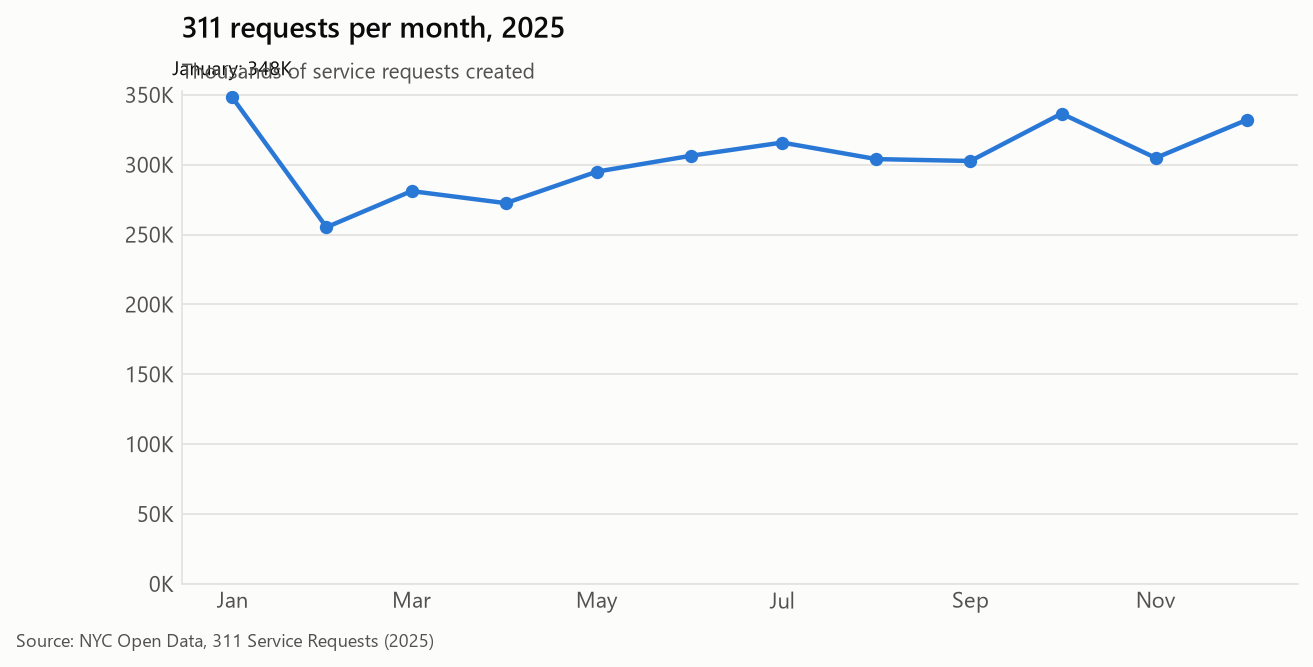

,0,1,2,3,4,5,6,7,8,9,10,11
month,2025-01-01 00:00:00,2025-02-01 00:00:00,2025-03-01 00:00:00,2025-04-01 00:00:00,2025-05-01 00:00:00,2025-06-01 00:00:00,2025-07-01 00:00:00,2025-08-01 00:00:00,2025-09-01 00:00:00,2025-10-01 00:00:00,2025-11-01 00:00:00,2025-12-01 00:00:00
requests,"348,081","255,235","281,085","272,458","295,003","306,385","315,819","303,989","302,622","336,576","304,807","332,064"


In [4]:
display(Image("../images/01_monthly_volume.png"))
results["monthly_volume"].assign(requests=lambda d: d.requests.map("{:,}".format)).T

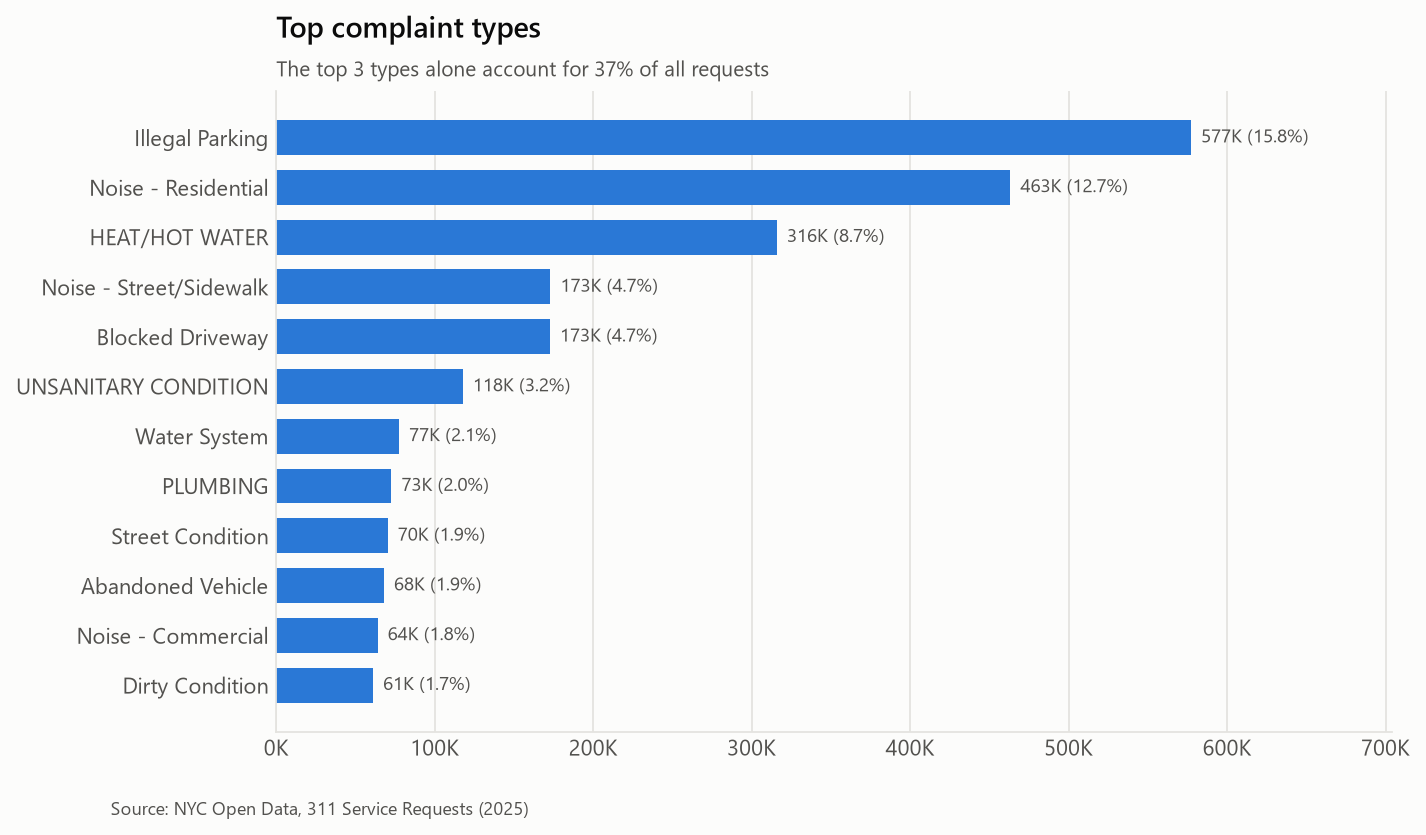

190 distinct complaint types in 2025


In [5]:
display(Image("../images/02_top_complaints.png"))
print(f"{int(results['complaint_type_count'].iloc[0, 0])} distinct complaint types in 2025")

Demand is highly concentrated. **Illegal parking, residential noise and heat/hot water
make up 37% of all requests**, and the top 15 types of 190 make up about two-thirds.
The first two go to NYPD, the third to HPD (Housing Preservation & Development).

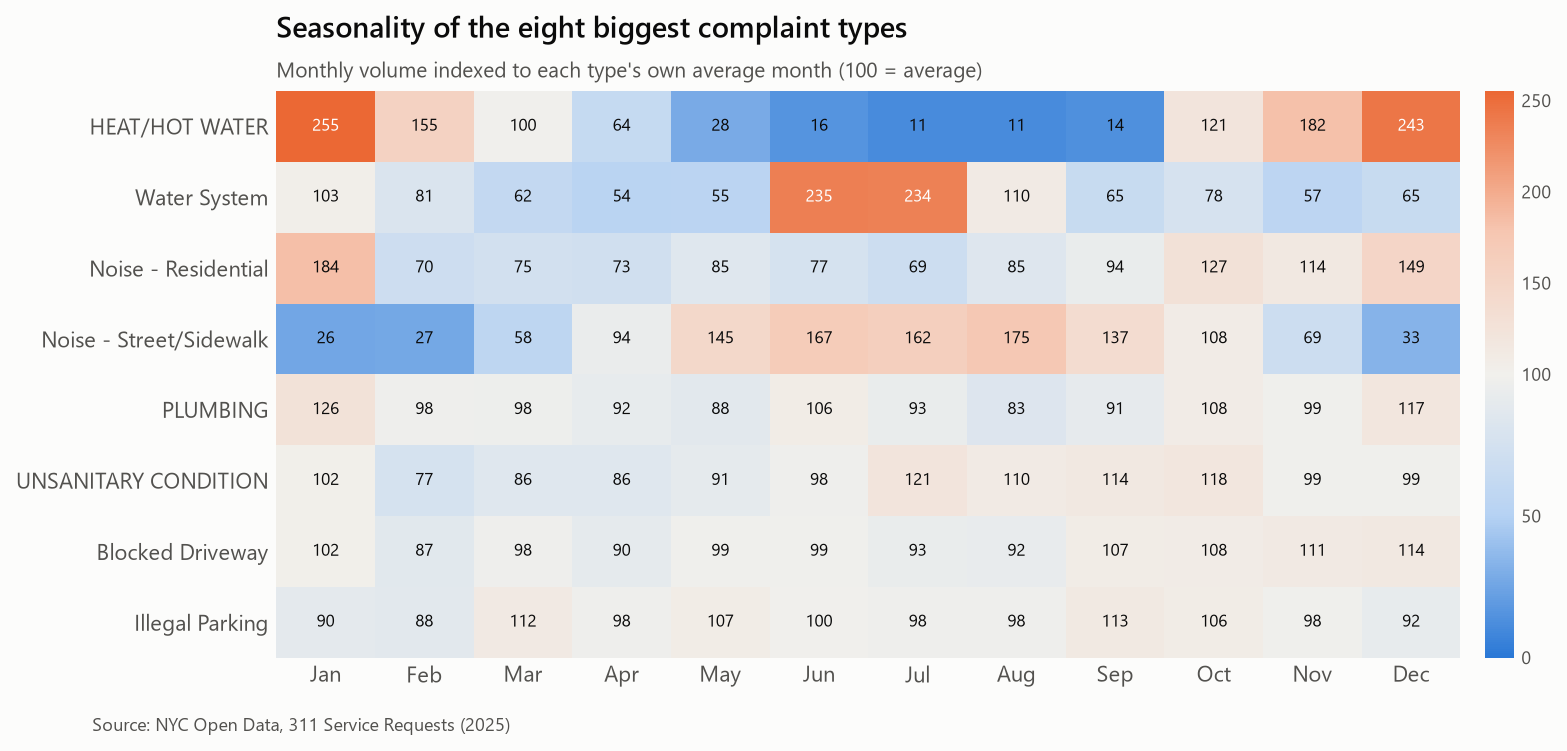

In [6]:
display(Image("../images/03_seasonality.png"))

Seasonality is strong and predictable, which makes it useful for staffing:

* **Heat/hot water** runs about 2.5× its average month in Dec–Jan and falls to about 11% of average in July–August.
* **Street/sidewalk noise** is the summer mirror image: 1.4–1.75× its average from May to September.
* **Water system** complaints spike to about 2.3× in June–July (open hydrants, pressure issues).
* **Residential noise** peaks in January (184) and December (149), driven by the holidays and New Year's.
* Parking and driveway complaints are flat all year, so they are a structural load, not a seasonal one.

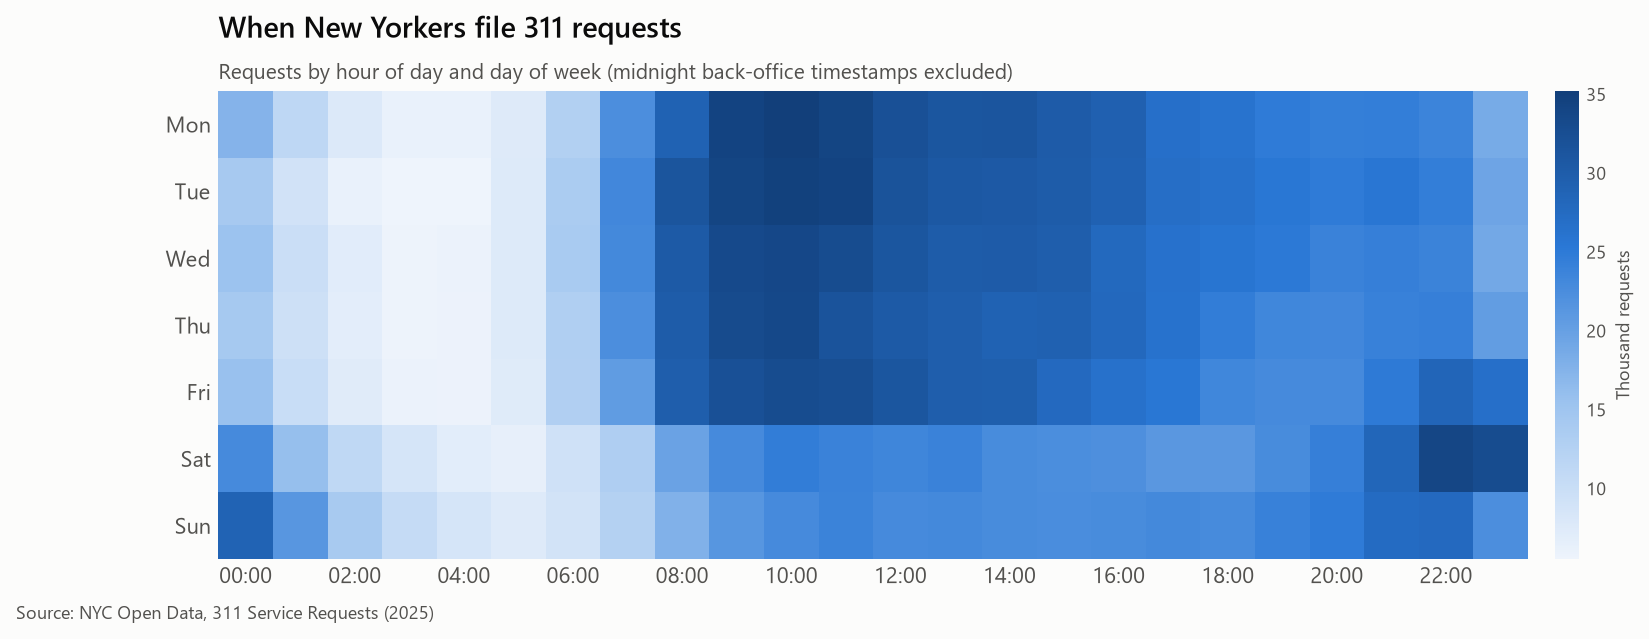

In [7]:
display(Image("../images/04_hour_weekday.png"))

Weekday requests peak from 9 to 11 am, when people report problems they found overnight or on the way to work.
Weekends shift late: **Friday and Saturday 10 pm to 1 am is a second peak**, and 60% of it is noise complaints.
That is the window when NYPD's 311 load is highest.

In [8]:
results["channel_mix"]

,channel,requests,pct
0,ONLINE,1564702,42.8
1,PHONE,970039,26.5
2,MOBILE,856033,23.4
3,UNKNOWN,263291,7.2
4,OTHER,59,0.0


Only about a quarter of requests come in by phone. Online (43%) and mobile app (23%)
together make up two-thirds, so digital intake is now the main front door.

## 3. Performance: how fast are requests closed?

Resolution times are extremely right-skewed: most close within hours, and a long tail runs for months.
I use **medians and 90th percentiles**, never means.

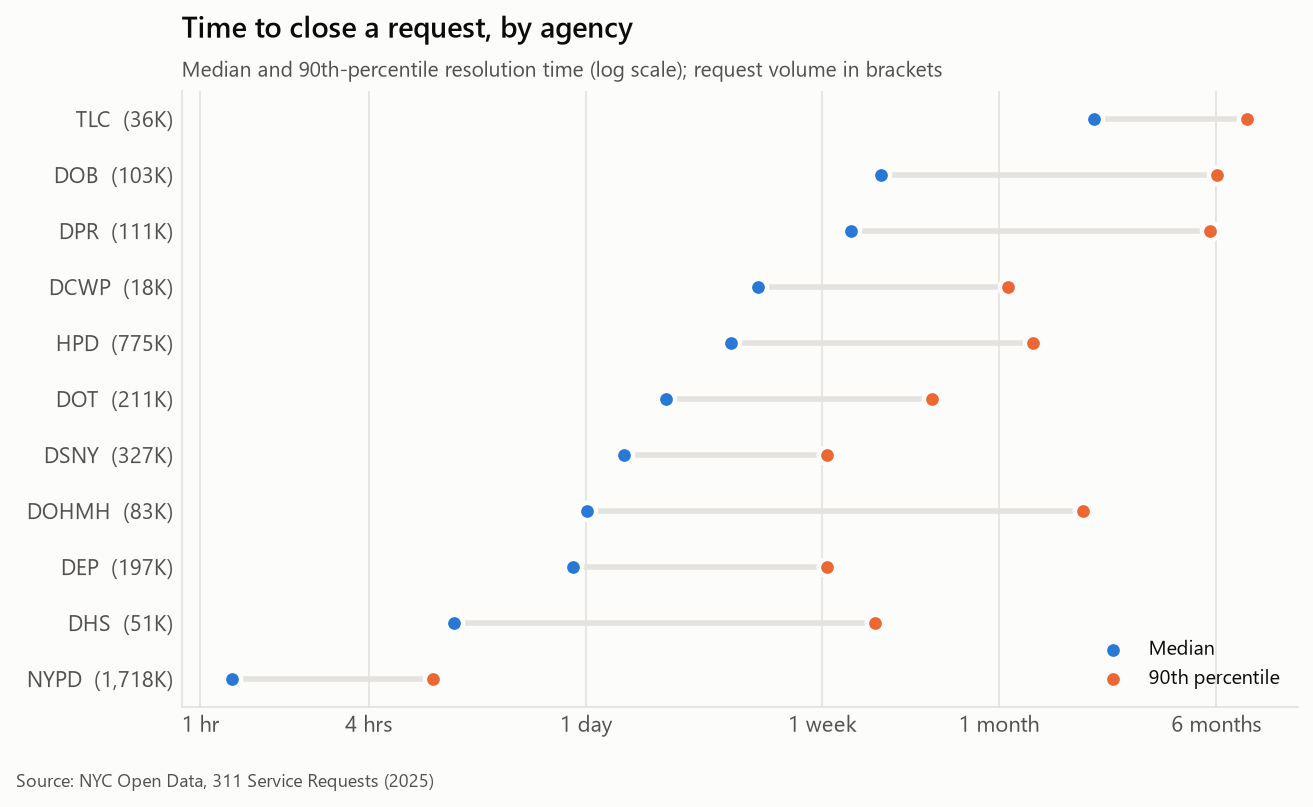

,agency,requests,pct_closed,median_hours,p90_hours,pct_within_1_day,pct_within_7_days
0,NYPD,1717526,100.0,1.3,6.8,99.0,100.0
1,HPD,774535,99.6,79.2,955.0,13.5,64.7
2,DSNY,326773,99.0,32.7,174.0,38.8,89.3
3,DOT,211268,97.6,46.3,414.4,39.5,72.8
4,DEP,197137,98.7,21.6,174.0,53.6,88.1
5,DPR,110855,85.8,212.5,"4,105.3",22.8,46.8
6,DOB,103066,100.0,273.6,"4,328.1",25.4,45.2
7,DOHMH,83396,95.7,24.2,"1,440.5",49.3,63.7
8,DHS,51449,88.4,8.1,259.2,72.4,87.3
9,TLC,36225,81.2,"1,581.3","5,558.6",8.8,22.5


In [9]:
display(Image("../images/05_agency_resolution.png"))
results["agency_performance"]

* **NYPD** closes 99% of its 1.7M requests within a day (median 1.3 h). A caveat: "closed"
  means the call was responded to, not that the problem was fixed. Many noise and parking
  complaints close as "officers responded, no violation observed".
* **HPD** is the operational bottleneck by volume × time: 775K requests, median 3.3 days,
  **p90 of 40 days**, and only 65% closed within a week.
* **DOB** (buildings) and **DPR** (parks and trees) have the longest tails: p90 of 170–180 days.
* **TLC** has a median of 66 days. Taxi complaints go through an adjudication process, so this is expected.

In [10]:
results["complaint_performance"].head(15)

,complaint_group,primary_agency,requests,pct_closed,median_hours,p90_hours
0,Illegal Parking,NYPD,577253,100.0,1.5,7.1
1,Noise - Residential,NYPD,463310,100.0,1.2,8.1
2,HEAT/HOT WATER,HPD,315946,99.5,39.4,76.0
3,Noise - Street/Sidewalk,NYPD,173036,100.0,0.9,4.0
4,Blocked Driveway,NYPD,172723,100.0,1.7,7.8
5,UNSANITARY CONDITION,HPD,117749,99.7,254.5,"1,541.7"
6,Water System,DEP,77487,98.3,3.6,193.8
7,PLUMBING,HPD,72657,99.6,194.9,"1,664.3"
8,Street Condition,DOT,70324,95.1,26.0,140.1
9,Abandoned Vehicle,NYPD,67903,100.0,2.1,10.7


In [11]:
results["open_backlog"].head(10)

,agency,complaint_group,still_open,oldest_open
0,EDC,Noise - Helicopter,9673,2025-02-03
1,DHS,Homeless Person Assistance,5990,2025-01-01
2,DPR,Overgrown Tree/Branches,5665,2025-01-01
3,DPR,Damaged Tree,3746,2025-01-01
4,DOT,Street Condition,3477,2025-01-01
5,DPR,Root/Sewer/Sidewalk Condition,2888,2025-01-02
6,TLC,For Hire Vehicle Complaint,2820,2025-01-01
7,TLC,Taxi Complaint,2562,2025-01-01
8,DPR,Dead/Dying Tree,1833,2025-01-01
9,DOT,Street Light Condition,1590,2025-01-01


The open backlog is concentrated in **tree work at DPR** (overgrown, damaged and dead trees,
root/sidewalk conditions: 14K+ requests still open), **TLC complaints**, and **DHS homeless-assistance** requests.

## 4. Equity: do some areas get slower service?

Comparing raw medians across boroughs is misleading, because each borough files a different
**mix** of complaints. Queens files many fast-closing parking complaints; Staten Island files
more slow street and tree issues.

**Method: complaint-mix-adjusted benchmark.** For each of the 112 complaint types with 500 or
more closed requests, I compute the citywide median resolution time. Then every request gets
a score: did it close faster than the citywide median for *its own* type? (Ties count as
half.) Citywide this is 50% by construction. An area below 50% is slower than the city norm
*after accounting for what its residents report*.

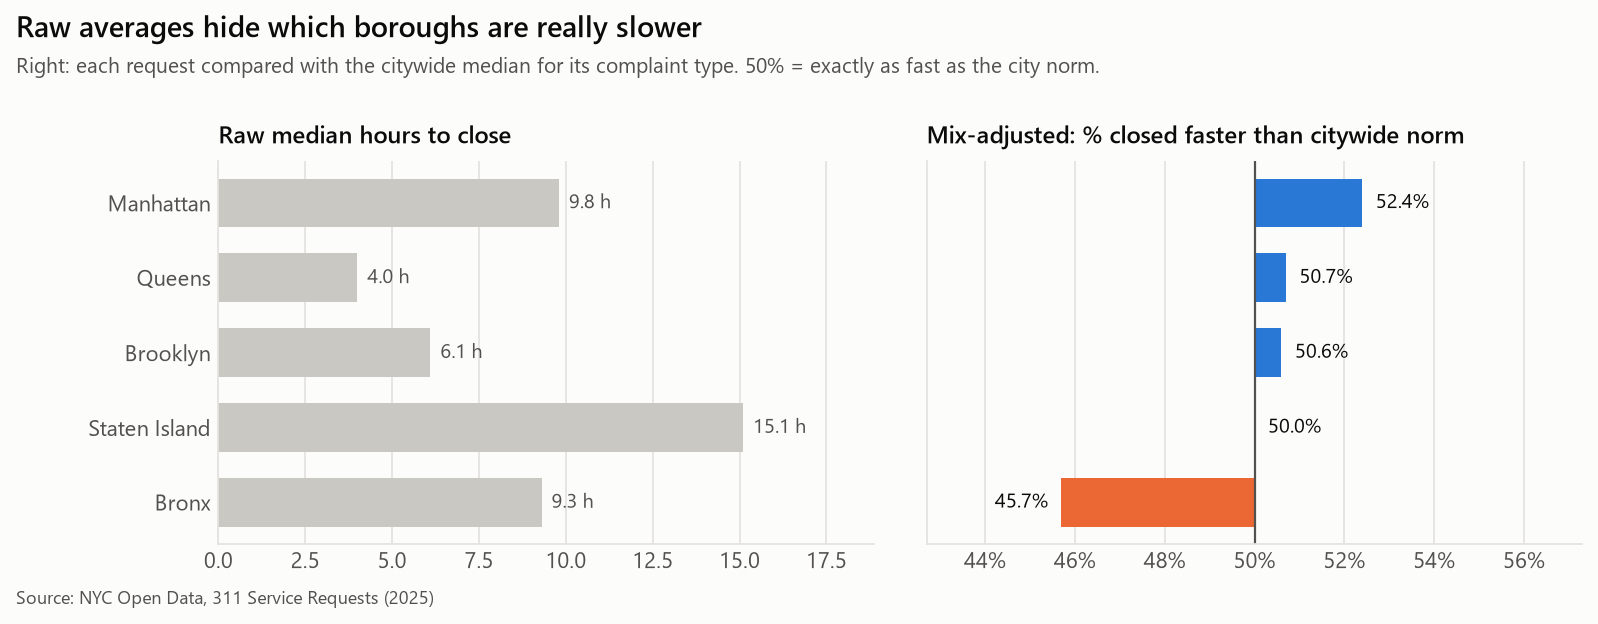

,borough,closed_requests,raw_median_hours,pct_faster_than_citywide
0,BRONX,830714,9.3,45.7
1,STATEN ISLAND,131353,15.1,50.0
2,BROOKLYN,1060857,6.1,50.6
3,QUEENS,858388,4.0,50.7
4,MANHATTAN,707117,9.8,52.4


In [12]:
display(Image("../images/06_borough_equity.png"))
results["borough_equity"]

The two views disagree. On raw medians, **Staten Island** looks slowest (15.1 h) and the Bronx
is middling. After adjusting for mix, Staten Island is exactly at the city norm, and **the Bronx
is the only borough clearly behind**: 45.7% of requests beat the benchmark, versus 50–52% elsewhere.

In [13]:
results["borough_equity_robustness"]

,borough,all_requests,excl_zero_duration,excl_nypd
0,BRONX,45.7,45.0,51.7
1,STATEN ISLAND,50.0,49.6,49.8
2,BROOKLYN,50.6,50.1,48.4
3,QUEENS,50.7,50.3,50.3
4,MANHATTAN,52.4,51.7,47.0


**Robustness.** The Bronx gap survives dropping zero-duration auto-closures (45.0%).
**But it disappears when NYPD is removed**: without NYPD, the Bronx scores 51.7%, *above*
the city norm. So the gap is not a general "Bronx gets worse city service" story. It is
specific to one agency.

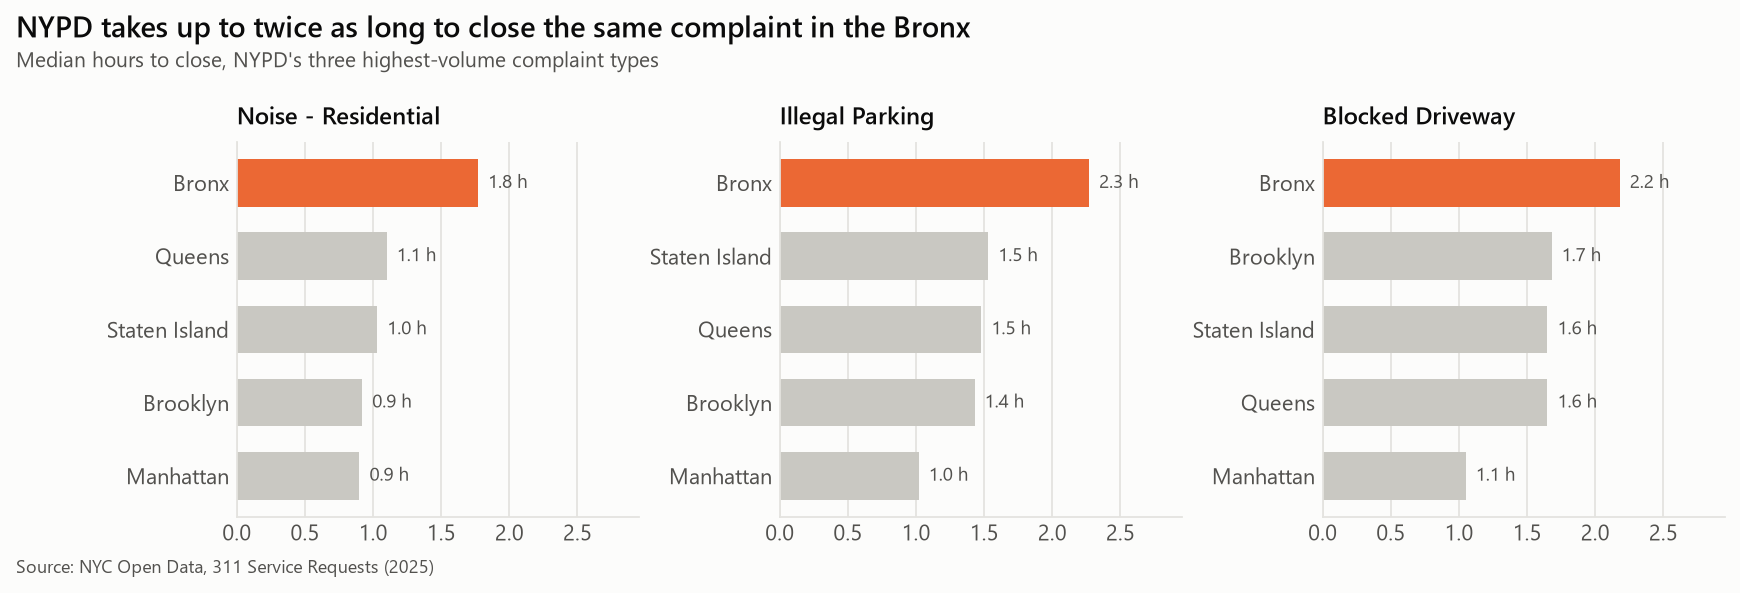

,complaint_group,borough,closed_requests,pct_of_citywide,median_hours
0,Blocked Driveway,BRONX,27113,15.7,2.2
1,Blocked Driveway,BROOKLYN,61840,35.8,1.7
2,Blocked Driveway,STATEN ISLAND,5157,3.0,1.6
3,Blocked Driveway,QUEENS,74217,43.0,1.6
4,Blocked Driveway,MANHATTAN,4394,2.5,1.1
5,Illegal Parking,BRONX,84418,14.6,2.3
6,Illegal Parking,STATEN ISLAND,17456,3.0,1.5
7,Illegal Parking,QUEENS,182171,31.6,1.5
8,Illegal Parking,BROOKLYN,228556,39.6,1.4
9,Illegal Parking,MANHATTAN,64634,11.2,1.0


In [14]:
display(Image("../images/08_nypd_core_types.png"))
results["nypd_core_types_by_borough"]

For NYPD's three biggest complaint types, the Bronx is slowest in every one:

* **Residential noise:** 1.8 h median in the Bronx vs 0.9 h in Brooklyn and Manhattan, about **2× slower**.
* **Illegal parking:** 2.3 h vs 1.0 h in Manhattan.
* **Blocked driveway:** 2.2 h vs 1.1–1.7 h elsewhere.

The likely driver is **load**. The Bronx filed **45% of all residential-noise complaints in
the city (209K)** with roughly 17% of the population (2020 Census). Bronx Community District 12
alone filed 131K noise complaints, more than all of Manhattan.

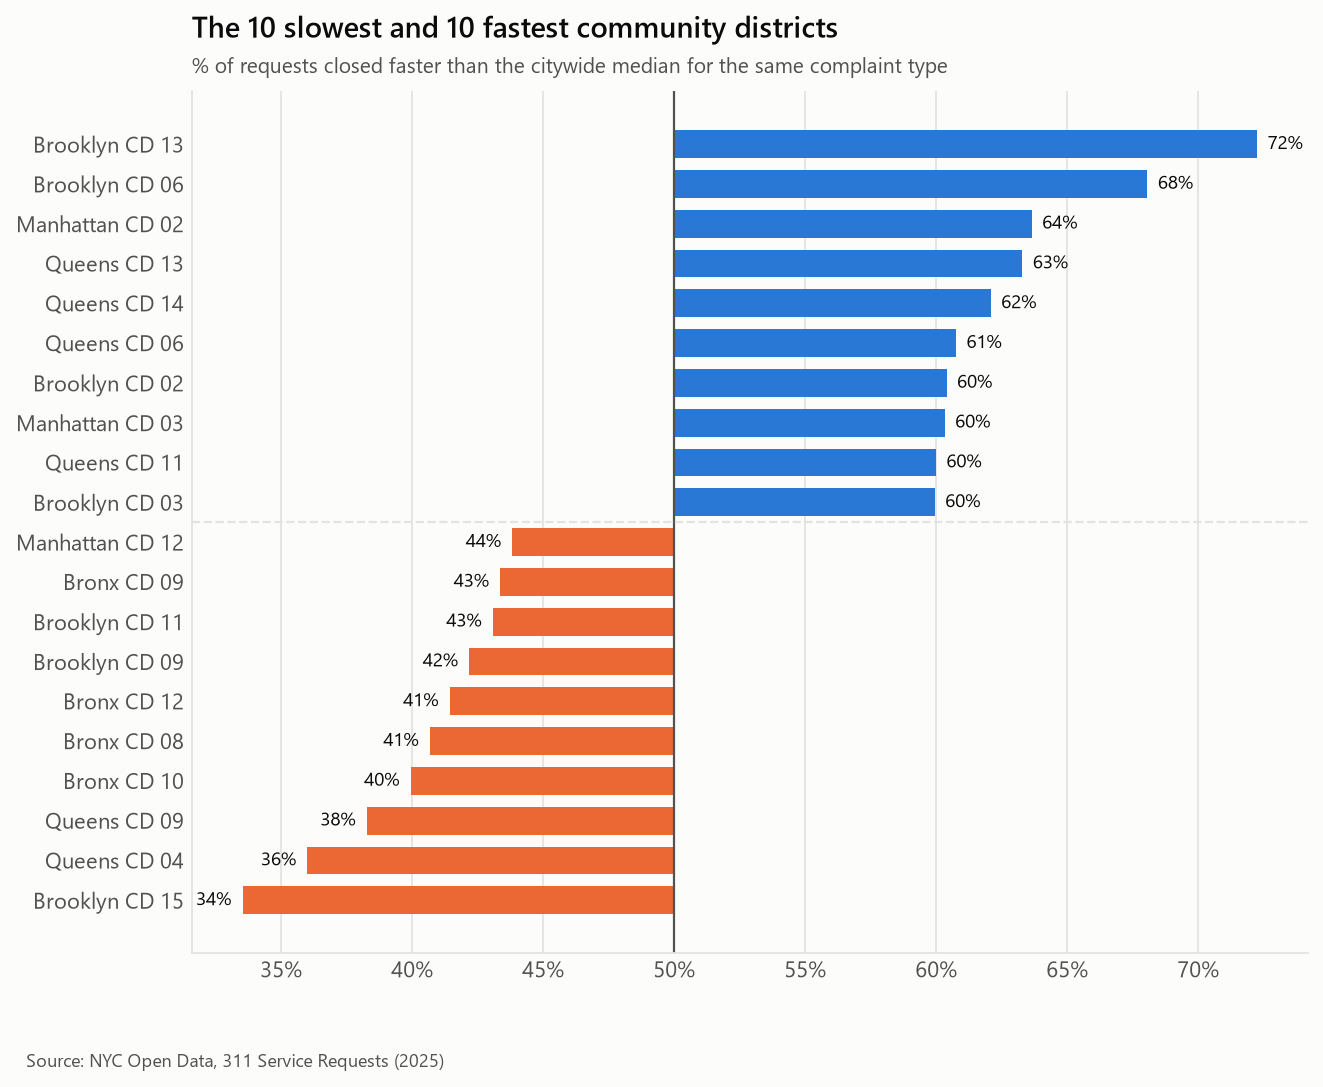

,community_board,borough,closed_requests,raw_median_hours,share_faster
0,15 BROOKLYN,BROOKLYN,59684,15.2,0.3
1,04 QUEENS,QUEENS,54742,3.8,0.4
2,09 QUEENS,QUEENS,60928,4.6,0.4
3,10 BRONX,BRONX,40923,9.2,0.4
4,08 BRONX,BRONX,54926,8.2,0.4
5,12 BRONX,BRONX,198760,3.6,0.4
6,09 BROOKLYN,BROOKLYN,48695,19.9,0.4
7,11 BROOKLYN,BROOKLYN,66296,4.7,0.4
8,09 BRONX,BRONX,60926,14.0,0.4
9,12 MANHATTAN,MANHATTAN,111391,13.0,0.4


In [15]:
display(Image("../images/07_district_ranking.png"))
results["district_equity"].head(10)

In [16]:
results["slowest_district_drilldown"]

,community_board,complaint_group,agency,closed_requests,district_median_hours,citywide_median_hours,pct_faster_than_citywide
0,15 BROOKLYN,Illegal Parking,NYPD,14663,7.1,1.5,17.8
1,15 BROOKLYN,Noise - Residential,NYPD,6047,3.6,1.2,24.1
2,15 BROOKLYN,Blocked Driveway,NYPD,5627,6.4,1.7,22.3
3,15 BROOKLYN,HEAT/HOT WATER,HPD,3886,39.0,39.4,50.5
4,15 BROOKLYN,Abandoned Vehicle,NYPD,2269,14.5,2.1,11.2
5,15 BROOKLYN,General Construction/Plumbing,DOB,1481,183.2,106.5,44.6
6,15 BROOKLYN,Dirty Condition,DSNY,1273,23.8,23.3,48.8
7,15 BROOKLYN,UNSANITARY CONDITION,HPD,1200,179.6,254.5,61.3
8,15 BROOKLYN,Derelict Vehicles,DSNY,1090,15.6,21.0,68.9
9,15 BROOKLYN,Water System,DEP,1028,15.4,3.6,35.1


At district level the spread is much wider than between boroughs: from **34% (Brooklyn CD 15:
Sheepshead Bay, Manhattan Beach)** to **72% (Brooklyn CD 13: Coney Island)**. These two
neighboring districts share a borough but have very different experiences. In CD 15, NYPD
illegal-parking complaints take a **7.1 h median against a 1.5 h citywide norm**, and only
18% beat the benchmark.

## 5. Recommendations

1. **Investigate NYPD 311 response capacity in the Bronx and in Brooklyn CD 15 / Queens CD 4 and 9.**
   The gap is agency-specific and concentrated in a few precincts. Compare call load per
   available unit by precinct, especially Friday and Saturday 10 pm to 1 am.
2. **Target HPD's long tail, not its median.** Unsanitary-condition, door/window, leak and
   plumbing cases take a median of 8–12 days and a p90 of 64–77 days. A triage SLA for
   cases open more than 30 days would hit the part of the distribution residents feel.
3. **Staff for seasonality.** Heat complaints (Nov–Feb) and water-system complaints
   (Jun–Jul) swing up to 20× within a year and are predictable months ahead.
4. **Fix the data before the dashboard.** DOT's closed-before-created timestamps and EDC's
   bulk-closed helicopter complaints distort any agency-level KPI built on this feed.
5. **Report mix-adjusted metrics.** Raw borough medians would have pointed attention at
   Staten Island, which is the wrong place.

## Limitations
* "Closed" is an administrative status, not proof the problem was fixed.
* Mix adjustment controls for complaint type, not for severity within a type or for address-level repeat callers.
* No population denominator is joined at district level, so request volume is not normalized per resident.
* Observational data: the analysis identifies *where* service is slower, not *why*. The load explanation is a hypothesis for the recommended follow-up.